# IDP: Monotonic Neural Inventory Control

This notebook compares an unconstrained MLP, a soft monotonicity-penalty MLP, and strictly monotone MonoKAN on the common lost-sales benchmark. Neural policies optimize simulated reward. MAE and RMSE are evaluation metrics against held-out oracle base-stock actions. A monotonicity violation occurs when order quantity increases between adjacent increasing inventory states.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "inventory_control").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from inventory_control.idp_benchmark import run_idp_benchmark

PROFILE = "auto"  # auto, compact, or full
full_dir = ROOT / "outputs" / "idp_benchmark" / "full_validation"
compact_dir = ROOT / "outputs" / "idp_benchmark" / "compact_validation"
if PROFILE == "full":
    artifact_dir = full_dir
elif PROFILE == "compact":
    artifact_dir = compact_dir
else:
    artifact_dir = full_dir if (full_dir / "summary.csv").exists() else compact_dir

if not (artifact_dir / "summary.csv").exists():
    run_idp_benchmark(profile="compact", split="validation", output_dir=compact_dir)
    artifact_dir = compact_dir

summary = pd.read_csv(artifact_dir / "summary.csv")
operational = pd.read_csv(artifact_dir / "operational_metrics.csv")
predictions = pd.read_csv(artifact_dir / "predictions.csv")
training = pd.read_csv(artifact_dir / "training_log.csv")
splines = pd.read_csv(artifact_dir / "monokan_splines.csv")
print(f"Loaded: {artifact_dir}")
summary

Loaded: c:\Users\Apple\Desktop\IDP_Inventory_Control\outputs\idp_benchmark\compact_validation


,policy_name,mean_total_reward,std_total_reward,mean_reward_per_period,service_level,lost_sales_rate,mean_order_quantity,mean_inventory,mae,rmse,raw_violation_rate,deployed_violation_rate,raw_max_violation,deployed_max_violation,parameter_count,training_seconds,selected_penalty_weight
0,HistoricalDemandBaseStock,199838.579468,212743.196741,3330.642991,0.668267,0.331733,50.324529,27.648989,3.031544,7.314991,0.0000,0.000000,0.000000,0.000000,NaN,NaN,NaN
1,OracleGammaBaseStock,211323.626041,228176.700843,3522.060434,0.670003,0.329997,52.283655,30.197419,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,NaN,NaN,NaN
2,UnconstrainedMLP,194904.281451,244814.263895,3248.404691,0.710754,0.289246,51.620143,32.751636,41.858848,59.578504,0.9375,0.760417,0.256692,0.256692,897.0,3.168179,NaN
3,PenaltyMLP,195023.667641,244957.698334,3250.394461,0.711123,0.288877,51.652536,32.824100,41.867231,59.583252,0.9375,0.760417,0.253090,0.253090,897.0,0.491927,10.0
4,MonoKAN,244409.426307,308510.580474,4073.490438,0.991838,0.008162,79.191406,216.355990,129.487807,183.774833,0.0000,0.000000,0.000000,0.000000,8673.0,6.149315,NaN


## Operational performance

Higher reward and service level are better. All policies use the same validation products and demand traces.

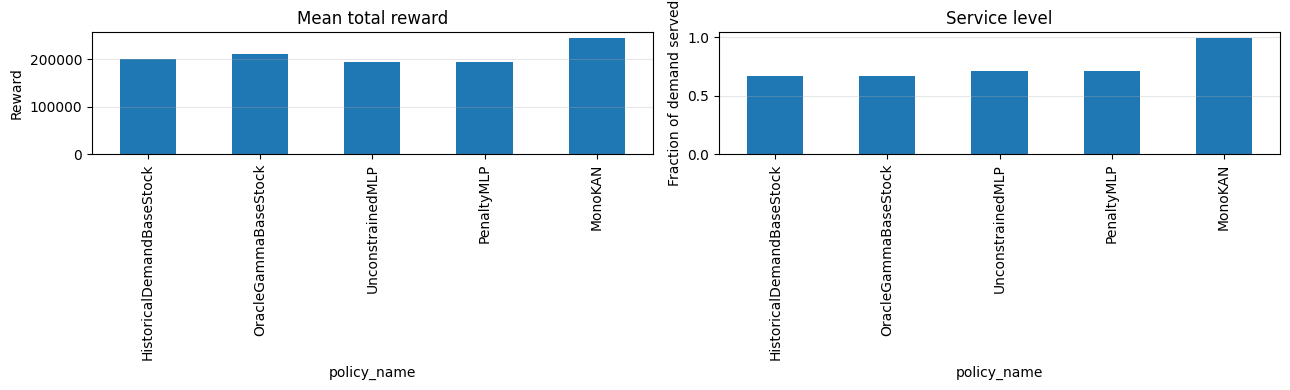

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
summary.set_index("policy_name")["mean_total_reward"].plot.bar(ax=axes[0], title="Mean total reward")
summary.set_index("policy_name")["service_level"].plot.bar(ax=axes[1], title="Service level")
axes[0].set_ylabel("Reward")
axes[1].set_ylabel("Fraction of demand served")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

## Oracle-action accuracy and monotonicity

MAE/RMSE compare deployed actions with oracle base-stock actions. Raw violations are measured before the common state-dependent action cap; deployed violations are measured after it.

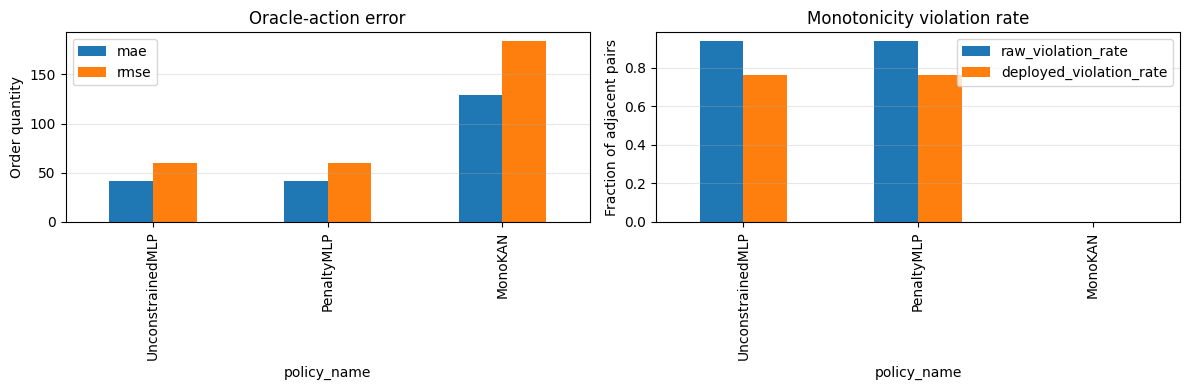

In [3]:
neural = summary[summary["policy_name"].isin(["UnconstrainedMLP", "PenaltyMLP", "MonoKAN"])].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
neural.set_index("policy_name")[["mae", "rmse"]].plot.bar(ax=axes[0], title="Oracle-action error")
neural.set_index("policy_name")[["raw_violation_rate", "deployed_violation_rate"]].plot.bar(
    ax=axes[1], title="Monotonicity violation rate"
)
axes[0].set_ylabel("Order quantity")
axes[1].set_ylabel("Fraction of adjacent pairs")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

## Learning efficiency

Curves show the selected runs. Phase 0 is imitation warm-starting and phase 1 is direct reward optimization.

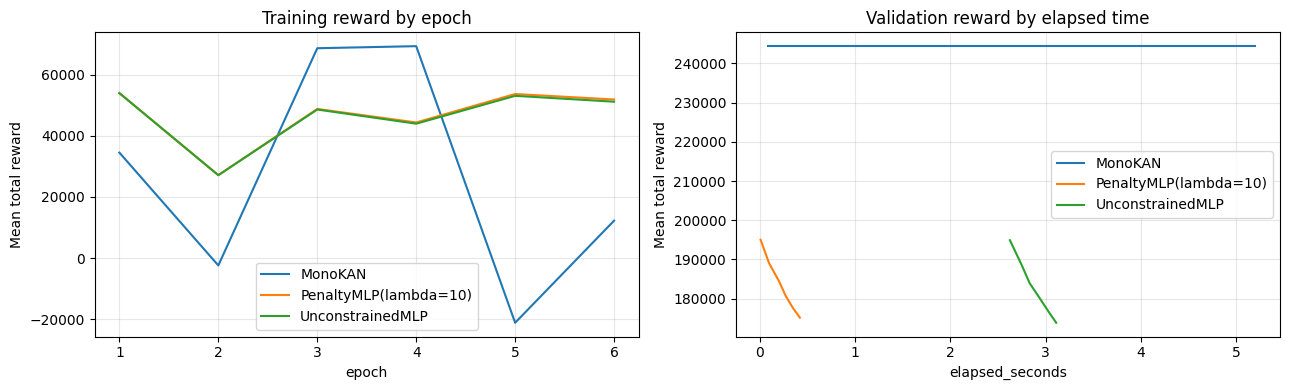

In [4]:
selected_training = training[training["selected"] == True]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, rows in selected_training.groupby("policy_name"):
    rows.plot(x="epoch", y="training_mean_total_reward", ax=axes[0], label=name)
    valid = rows.dropna(subset=["validation_mean_total_reward"])
    valid.plot(x="elapsed_seconds", y="validation_mean_total_reward", ax=axes[1], label=name)
axes[0].set_title("Training reward by epoch")
axes[1].set_title("Validation reward by elapsed time")
axes[0].set_ylabel("Mean total reward")
axes[1].set_ylabel("Mean total reward")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

## Learned policy structure

The policy curves hold product history and economics fixed while inventory increases.

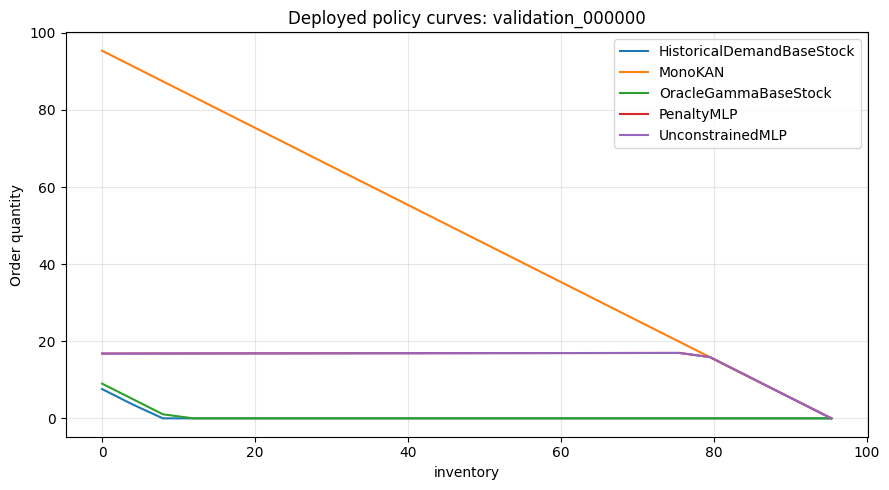

In [5]:
representative_product = predictions["product_id"].iloc[0]
curve = predictions[predictions["product_id"] == representative_product]
fig, ax = plt.subplots(figsize=(9, 5))
for name, rows in curve.groupby("policy_name"):
    rows.sort_values("inventory").plot(x="inventory", y="deployed_order", ax=ax, label=name)
ax.set_title(f"Deployed policy curves: {representative_product}")
ax.set_ylabel("Order quantity")
ax.grid(alpha=0.3)
plt.tight_layout()

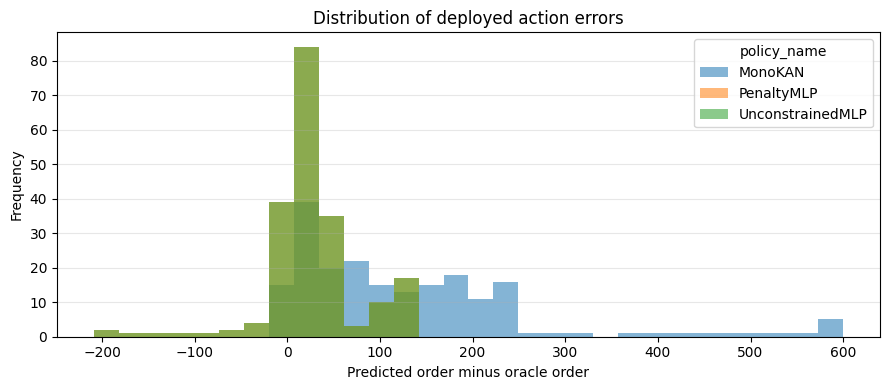

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
predictions[predictions["policy_name"].isin(["UnconstrainedMLP", "PenaltyMLP", "MonoKAN"])].pivot(
    columns="policy_name", values="error"
).plot.hist(bins=30, alpha=0.55, ax=ax)
ax.set_title("Distribution of deployed action errors")
ax.set_xlabel("Predicted order minus oracle order")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

## MonoKAN spline interpretation

Each line is the learned first-layer edge function from normalized inventory to one hidden unit, including its base and Hermite-spline terms.

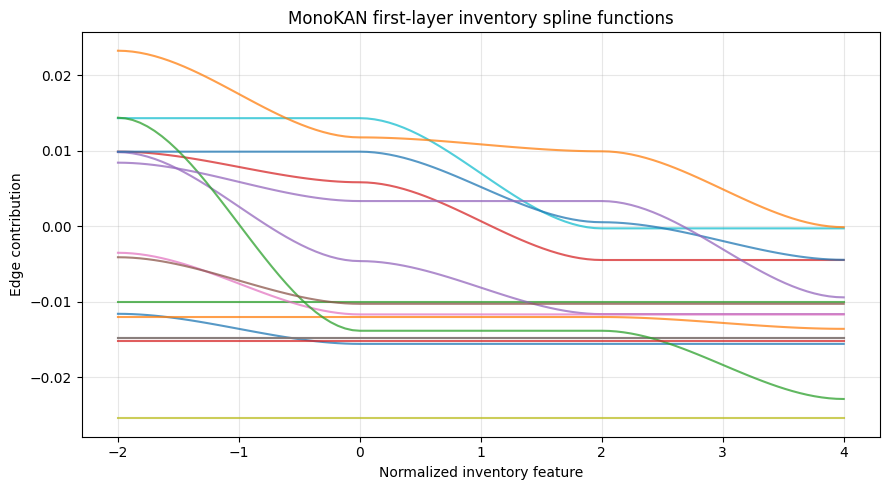

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for unit, rows in splines.groupby("hidden_unit"):
    rows.plot(x="inventory_feature", y="edge_value", ax=ax, label=f"unit {unit}", alpha=0.75)
ax.set_title("MonoKAN first-layer inventory spline functions")
ax.set_xlabel("Normalized inventory feature")
ax.set_ylabel("Edge contribution")
ax.grid(alpha=0.3)
if splines["hidden_unit"].nunique() > 8:
    ax.legend().remove()
plt.tight_layout()